In [1]:
#Run the following code to print multiple outputs from a cell
get_ipython().ast_node_interactivity = 'all'

# Polishing Visualizations

Last class, we looked at the basics for creating graphs with `gglot()`. In general, the layers of a basic `ggplot()` graph are as follows:

```
(ggplot(df, aes(map variables to the graphical elements)) +
   geometric_function())
```

Today, we're going to look at code to add titles/labels, to customize the graphical elements, and to annotate text, points, or lines. We simply add these layers as follows:

```
(ggplot(df, aes(map variables to the graphical elements)) +
   geometric_function() +
   labs(customize titles/labels) +
   scale...(customize the graphical elements) +
   annotate(add annotations to the graph))
```

Let's again import `plotnine` as well as the file, "dataBeatport.csv": 

In [2]:
from plotnine import *
import pandas as pd
df = pd.read_csv("dataBeatport.csv")
df

,genre,enteredCharts,twitterFollowers,artistSongs,labelSongs,daysAfterRelease
0,Deep House,0,1820,105,304,2
1,House,0,389,89,34,20
2,Trance,1,25141,231,781,23
3,Deep House,0,233,28,91,14
4,Deep House,0,168,104,121,16
...,...,...,...,...,...,...
11965,Deep House,0,567,159,40,23
11966,Techno,0,196,23,9,2
11967,Electro House,0,168,117,1319,2
11968,Electro House,0,1858,41,1319,2


## Review of `ggplot()` structure

To review what we covered last class, write code to create a scatter plot with the following elements:

* "labelSongs" is x and "daysAfterRelease" is y
* color the points by the "enteredCharts" variable (remember to use `factor()` to tell `ggplot()` to treat "enteredCharts" as a categorical variable)
* add "genre" as a shape element
* add "twitterFollowers" as a size element

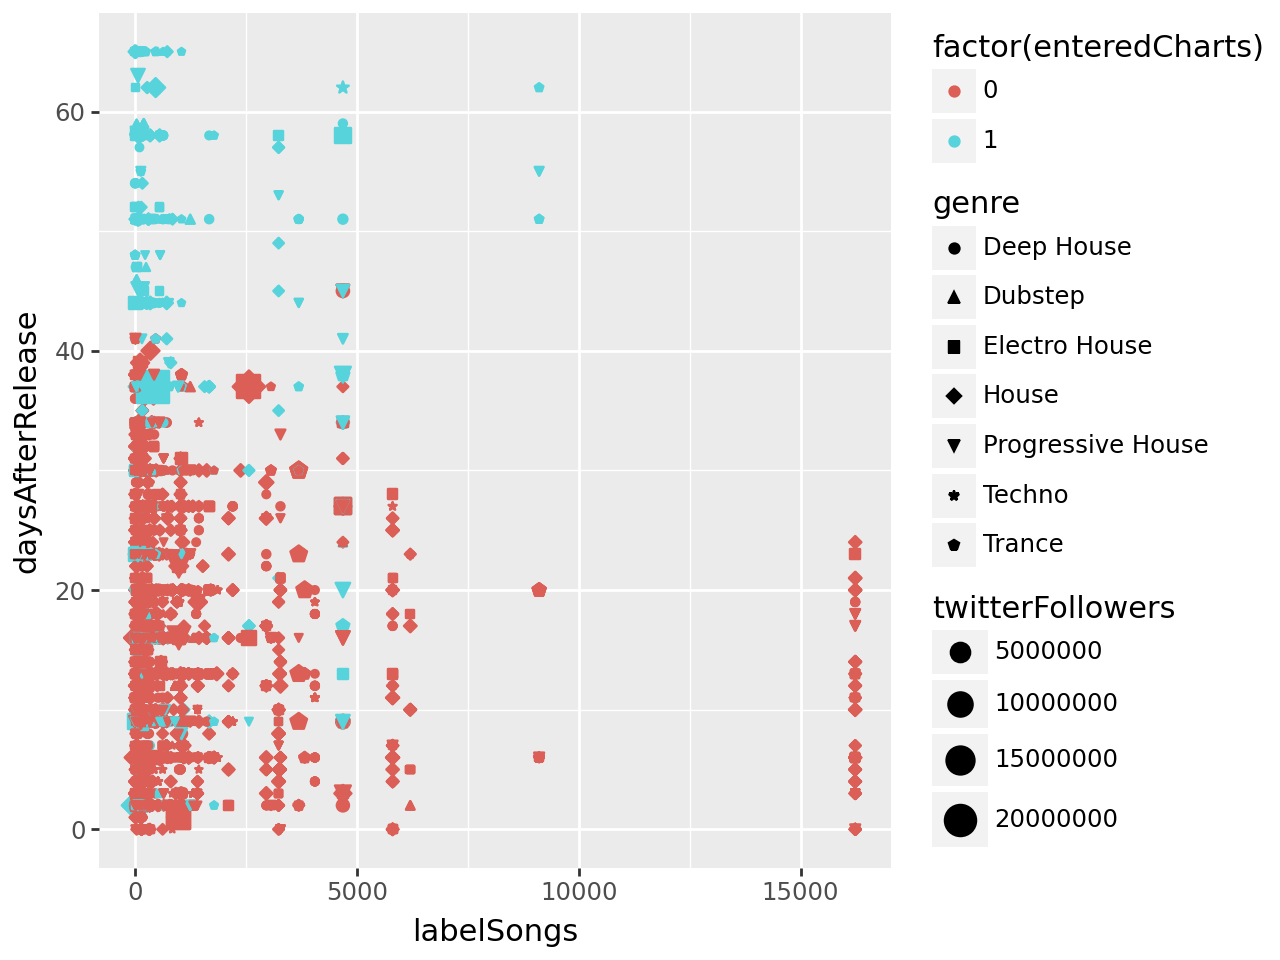

In [3]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point())

Let's start to customize this graph to make it easier to interpret.

## Titles/Labels

Use the `+ labs()` layer to customize your chart title and labels. Below, I've provided the `labs()` layer for the graph above...copy/paste that code to the cell below to include these labels:

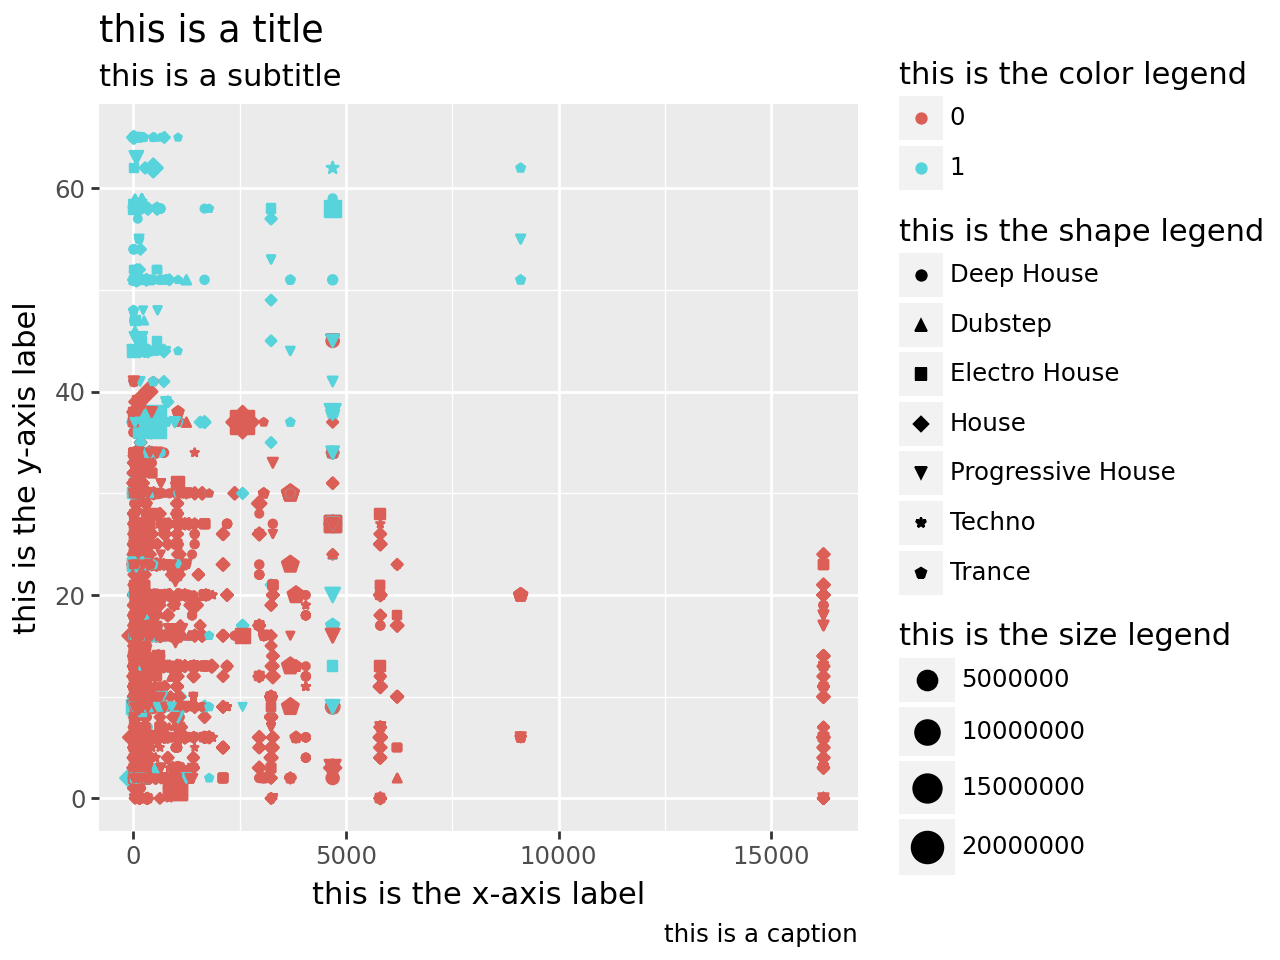

In [4]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "this is a title",
       subtitle = "this is a subtitle",
       caption = "this is a caption",
       x = "this is the x-axis label",
       y = "this is the y-axis label",
       color = "this is the color legend",
       shape = "this is the shape legend",
       size = "this is the size legend")
)

Copy/paste the code to the cell below and update the titles/labels with the following information:

* Title: "No relationship between Label Songs and Release Days"
* Subtitle: "Entered vs. Not Entered the Charts"
* Caption: "Source: dataBeatport.csv"
* x-axis: "# of Songs from the Label"
* y-axis: "Days after Release"
* color legend: "Entered the Charts?"
* shape legend: "Music Genre"
* size legend: "# of Twitter Followers"

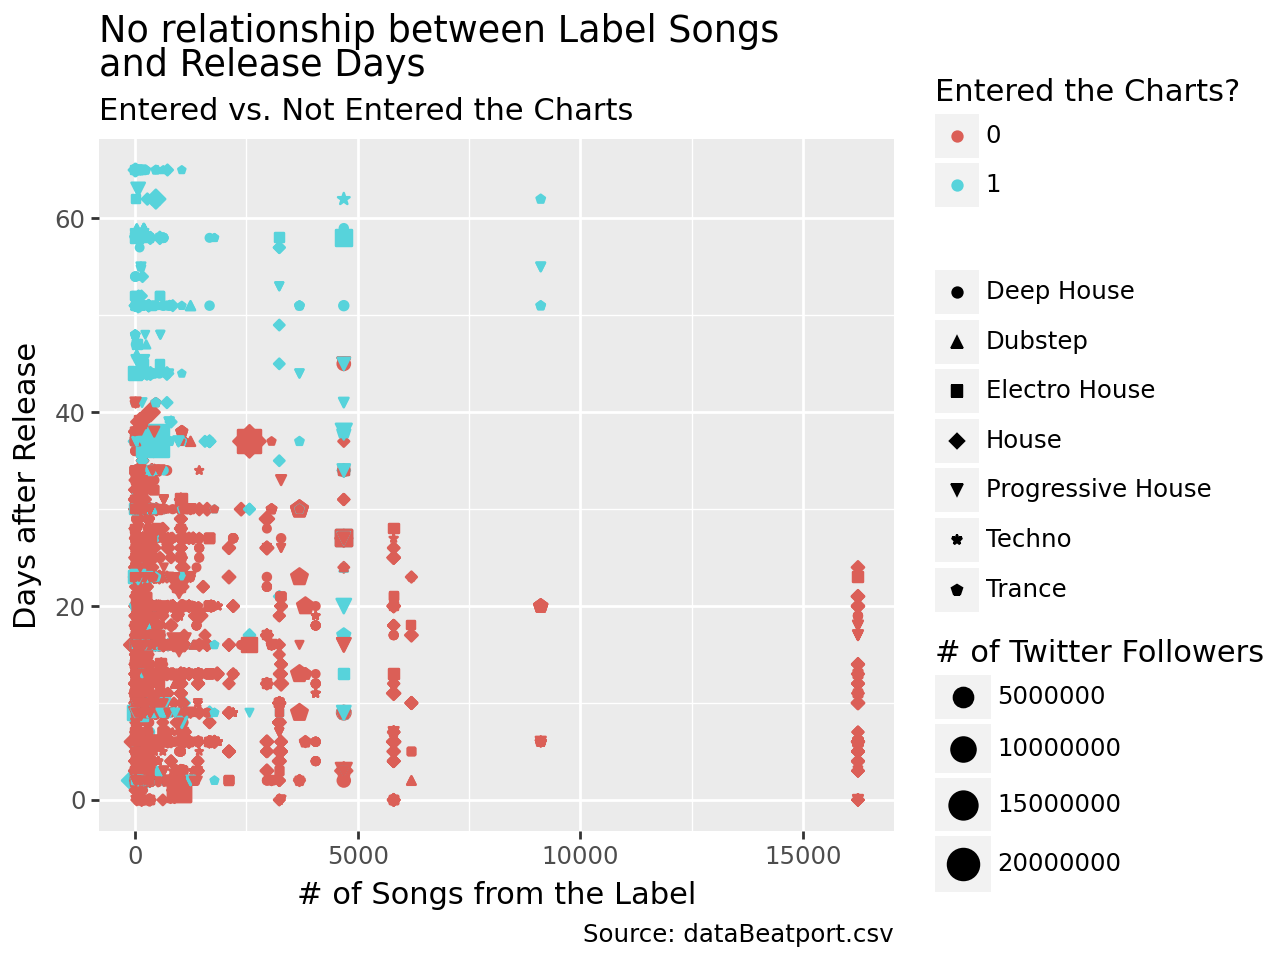

In [5]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "Entered the Charts?",
       shape = "",
       size = "# of Twitter Followers")
)

We don't really need the shape legend for Music Genre since the categories make it obvious. Can you figure out how to adjust your code to remove that title?

Also, I think the title might look better on 2 lines...to add a line break, you can use "\n" in your title. Add that before the word "and" and re-run your code.

## Scales

Now that we've labeled our graph, we can use scales to adjust the graphical elements for each variable. The structure of the scales layer is as follows:

```
   + scale_aestheticElement_discreteOrContinuous(settings)
```

For example: `scale_x_continuous(settings)` or `scale_color_discrete(settings)`, etc.

In our graph, we have variables mapped to `x`, `y`, `color`, `shape`, and `size`. So we'll use the following scales:

```
   + scale_x_continuous()
   + scale_y_continuous()
   + scale_color_discrete()
   + scale_shape_discrete()
   + scale_size_continuous()
```

### X and Y scales

Let's first look at the x- and y-axes. Both variables are continuous variables, so we'll use `scale_x_continuous()` and `scale_y_continuous()`.

Let's change the tick marks for the x axis with the `breaks` setting:

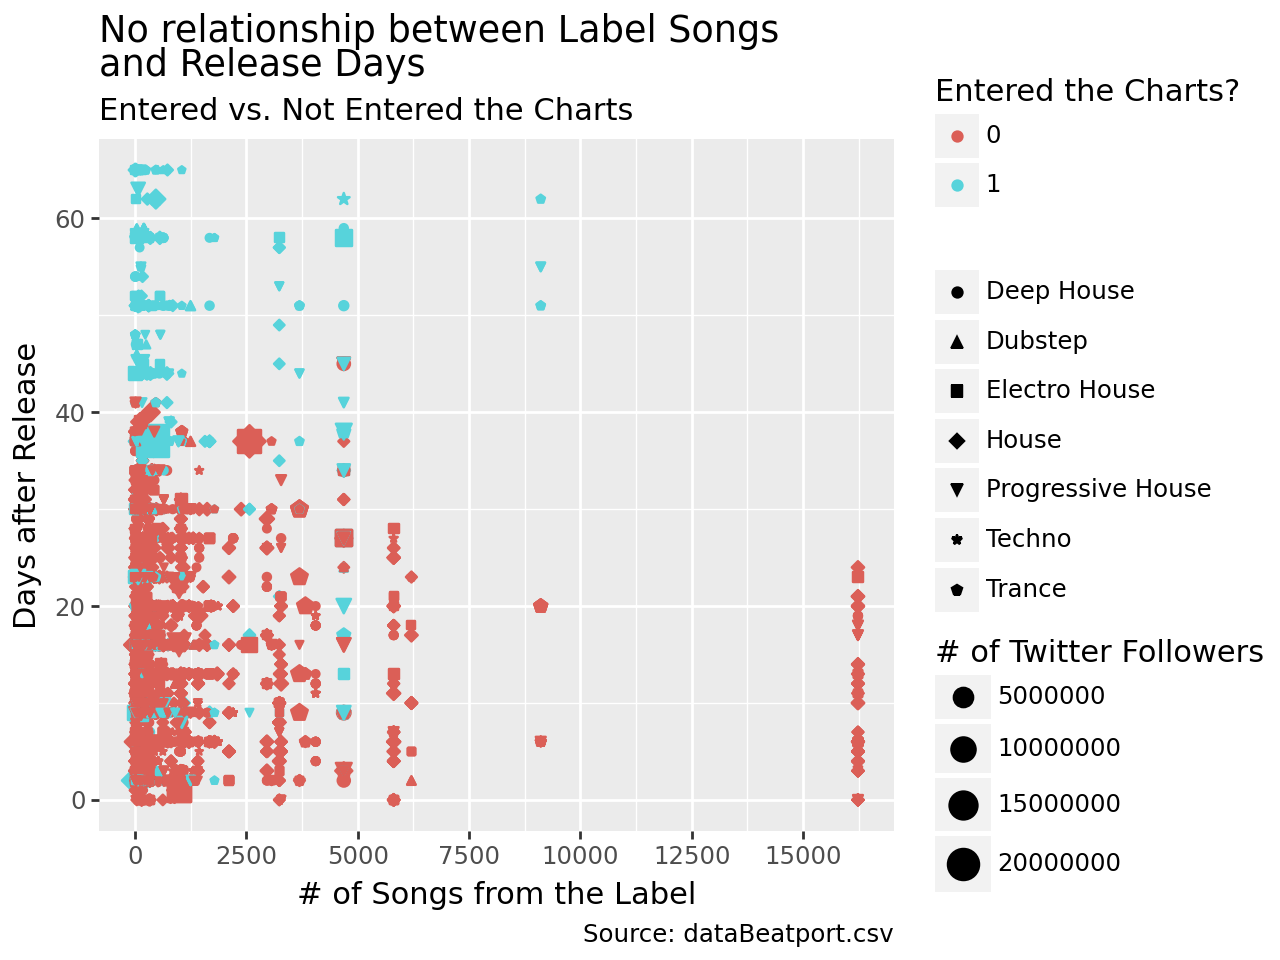

In [6]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "Entered the Charts?",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000])
                               # can also use numpy.arange(0, 15001, 2500)
)

We can also change the tick mark labels using the `label` setting. Let's abbreviate the tick mark labels using "k" to indicate thousands:

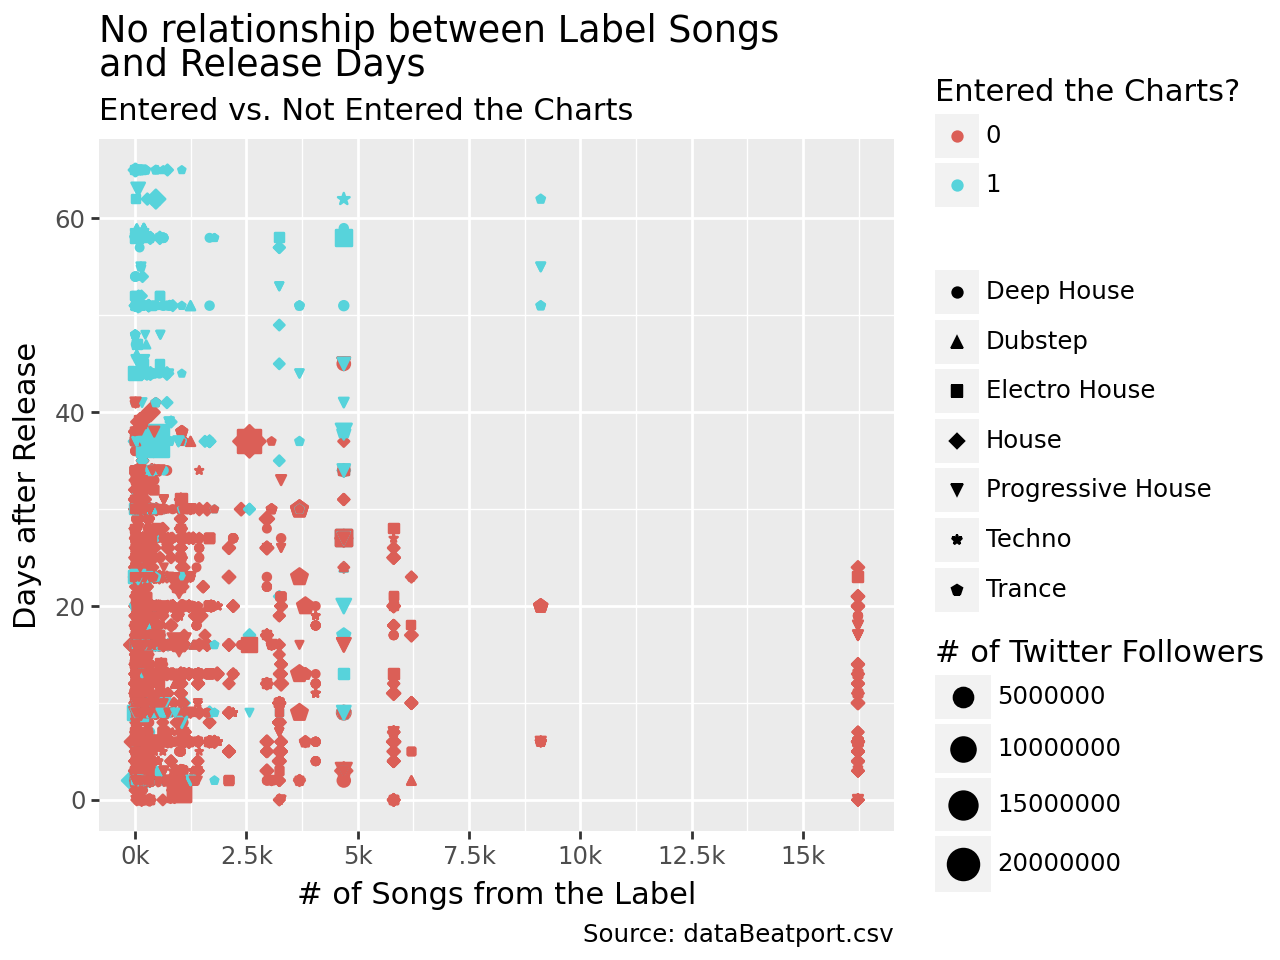

In [7]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "Entered the Charts?",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"])
)

What if you wanted to filter the "artistSongs" variable to only display a subset of data? You can use the `limits` setting:

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 239 rows containing missing values.


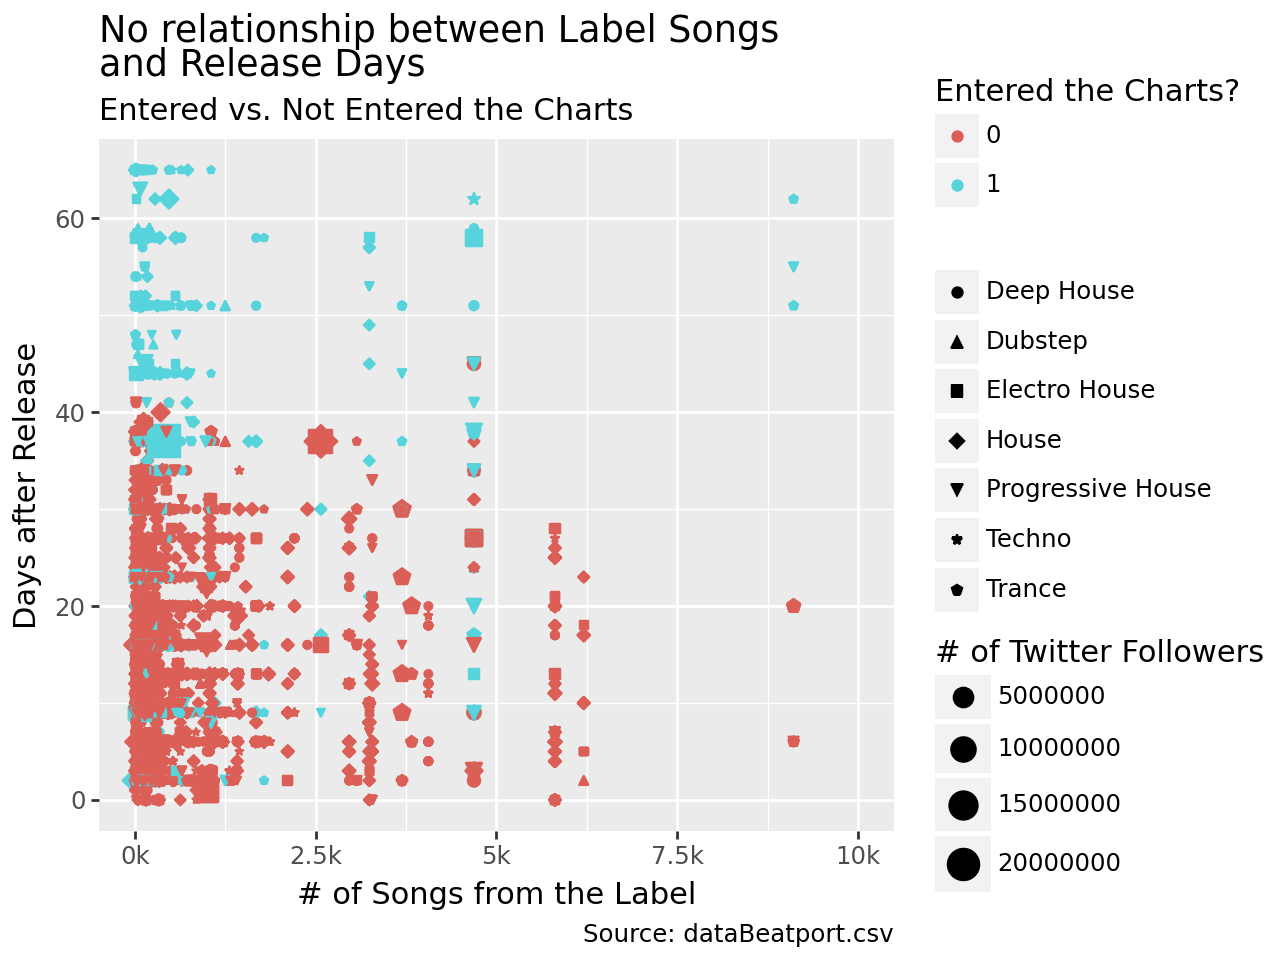

In [8]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "Entered the Charts?",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000])
)

To recap, we used `breaks`, `labels`, and `limits` to customize the x-axis. Now you try...customize the y-axis as follows:

* Display data for days 0 to 50 only
* Show tick marks for 0, 10, 20, 30, 40, and 50 days

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


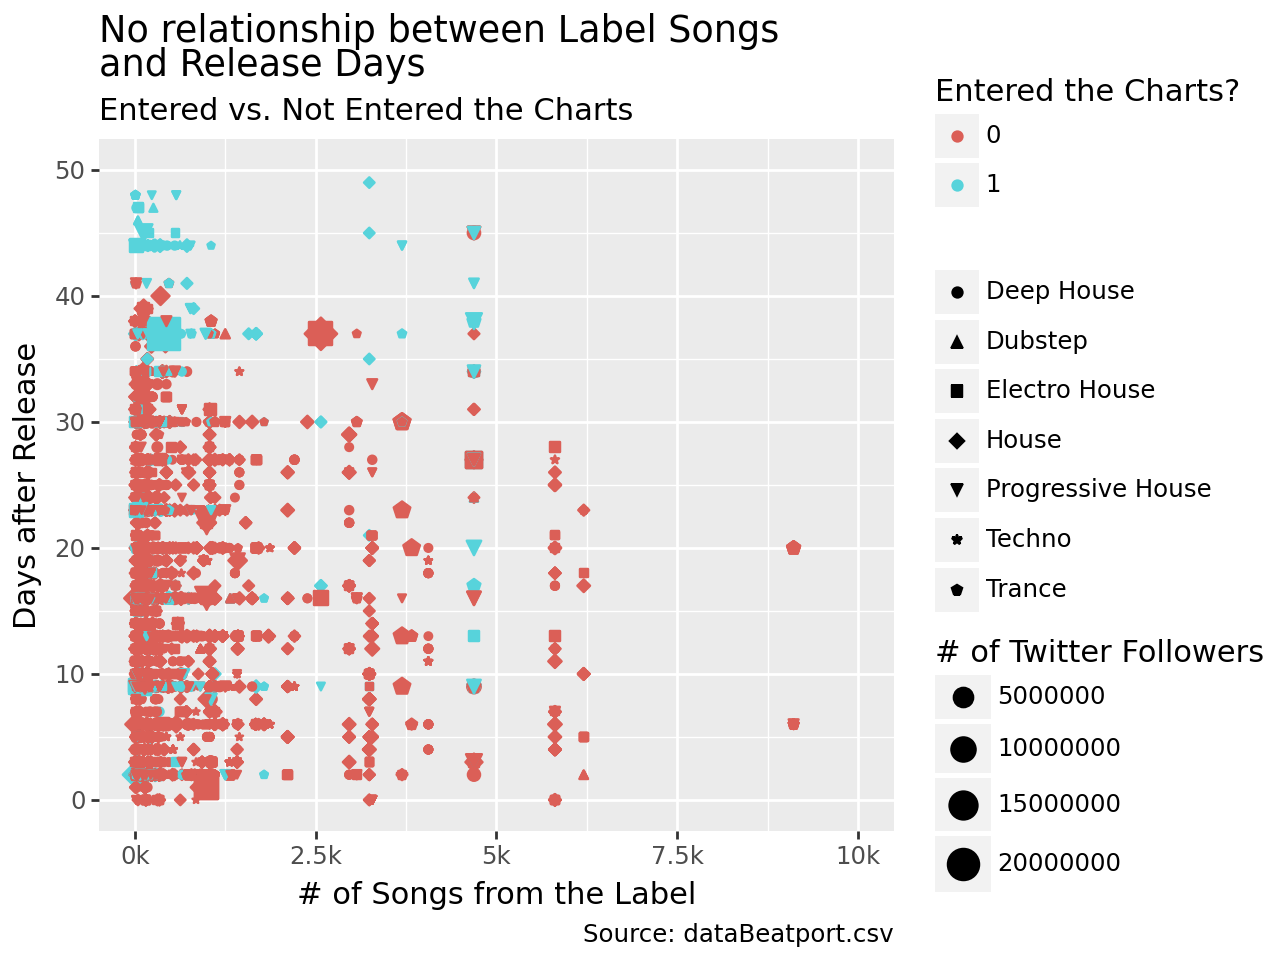

In [9]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "Entered the Charts?",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50])
)

### Color/Shape/Size Scales

We can also use `breaks`, `labels`, and `limits` for color, shape, and size aesthetic elements. The `breaks` set the values that are listed in each legend. For example, let's only show 5,000,000 and 20,000,000 in the size legend:

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


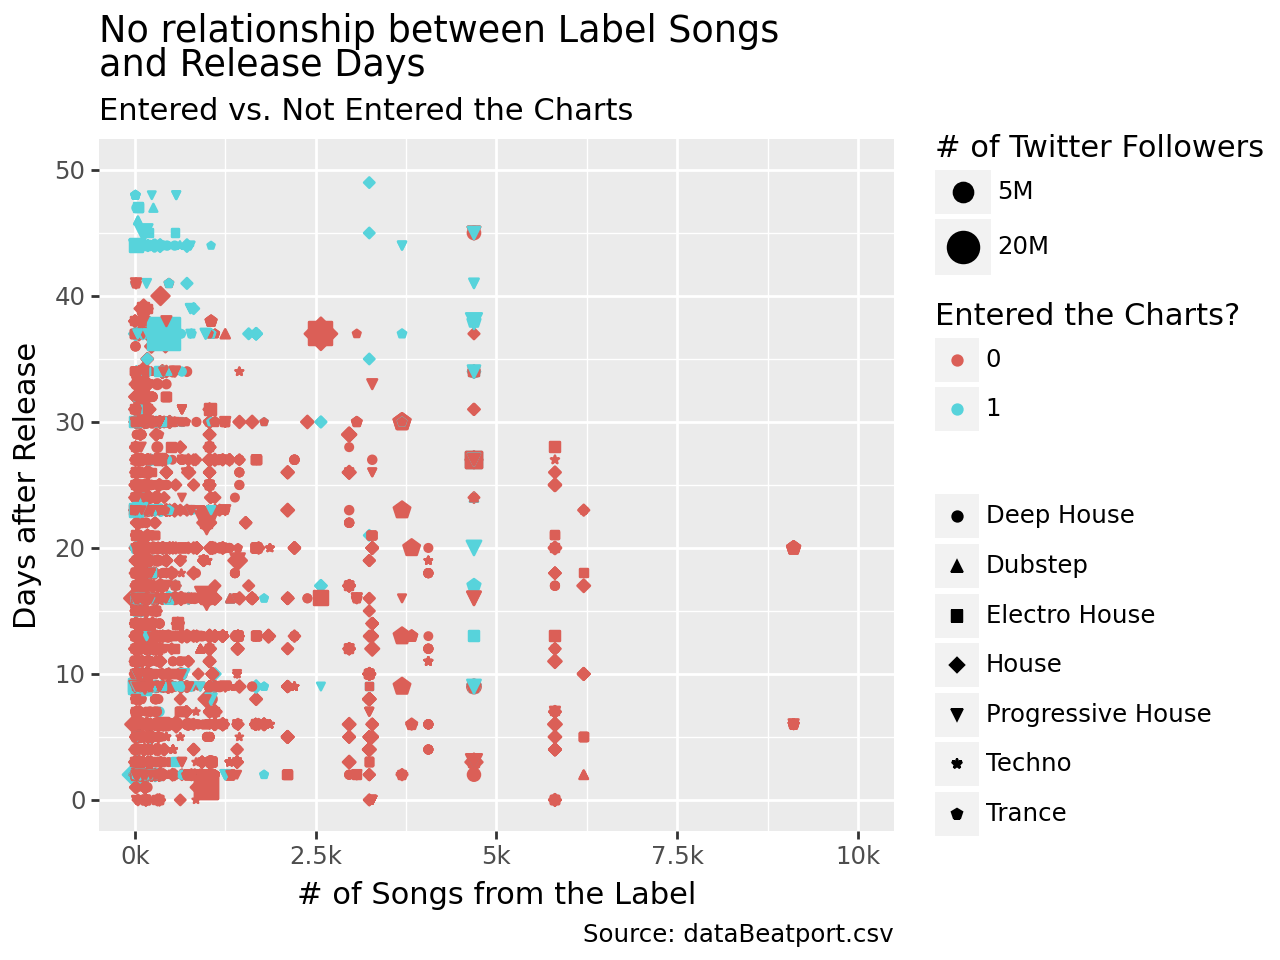

In [10]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "Entered the Charts?",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50]) +
   scale_size_continuous(breaks = [5000000, 20000000],
                        labels = ["5M", "20M"])
)

Now you try. For the color legend, let's re-label "0" as "Didn't enter charts" and "1" as "Entered charts". Also, since we're labeling the colors, let's remove the legend label.

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


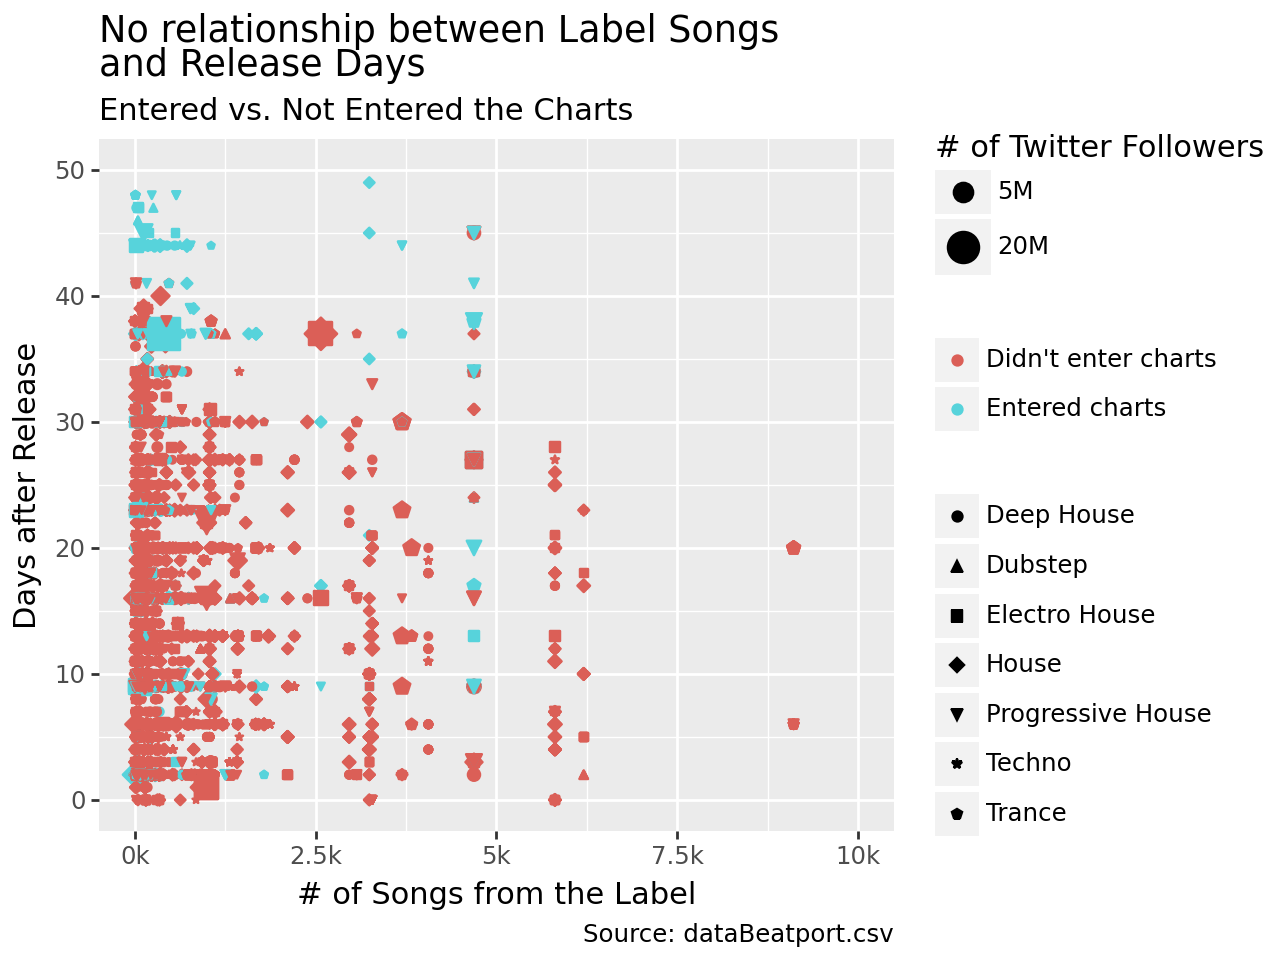

In [11]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50]) +
   scale_size_continuous(breaks = [5000000, 20000000],
                        labels = ["5M", "20M"]) +
   scale_color_discrete(labels = ["Didn't enter charts", "Entered charts"])
)

### Updating the Size range

An additional setting for the `size` scale is `range`, where you can set the range of the sizes:

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


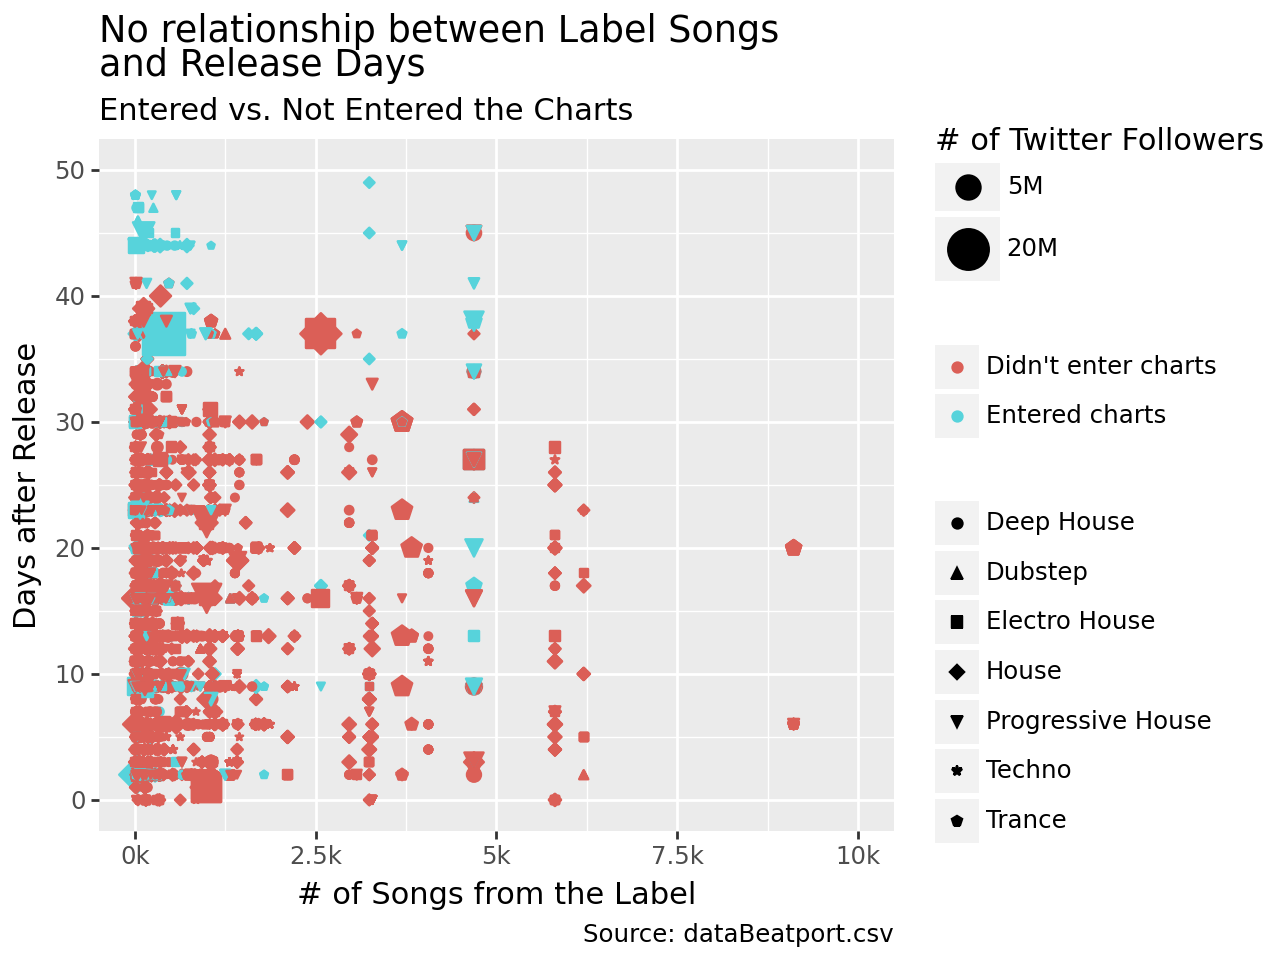

In [12]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50]) +
   scale_size_continuous(breaks = [5000000, 20000000],
                        labels = ["5M", "20M"],
                        range = [1,8]) +
   scale_color_discrete(labels = ["Didn't enter charts", "Entered charts"])
)

### Updating the Colors

For the `color` scale, you can specify the colors you'd like to use with the `values` setting. However, you also need to specifically use `scale_color_manual` when doing this:

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


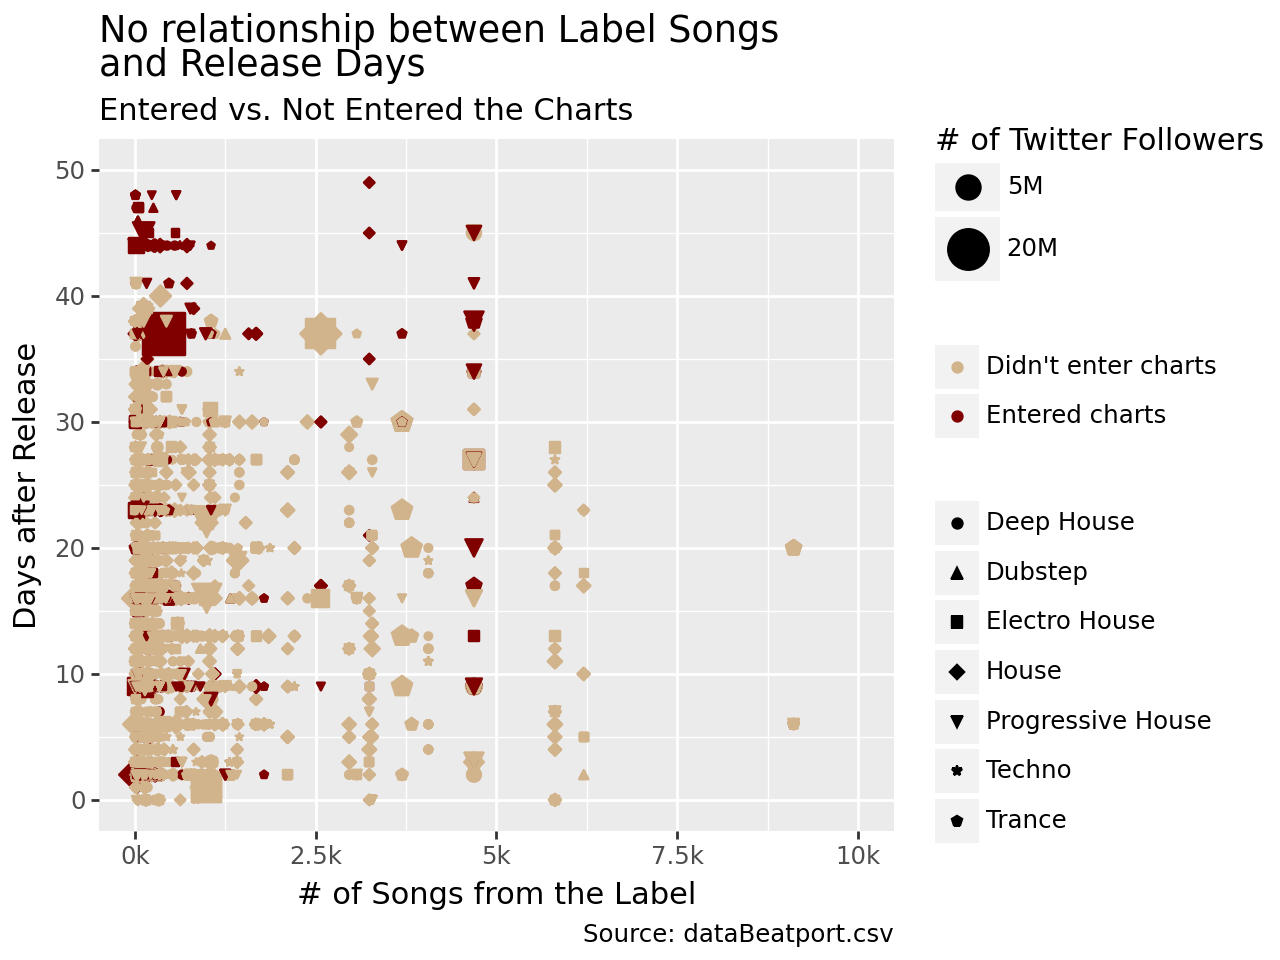

In [13]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50]) +
   scale_size_continuous(breaks = [5000000, 20000000],
                        labels = ["5M", "20M"],
                        range = [1,8]) +
   scale_color_manual(labels = ["Didn't enter charts", "Entered charts"],
                       values = ["tan", "maroon"])
   # could also use Hex codes, e.g., values = ["D2B48C", "800000"]
)

You can find codes for other colors here:  https://en.wikipedia.org/wiki/Web_colors.

#### Using Color Brewer to select pre-defined color palettes
If you'd like to use the pre-defined color palettes on the website, https://colorbrewer2.org, you can use the following scale layers:

```
   + scale_color_brewer()     #for discrete variables
   + scale_color_distiller()  #for continuous variables
```

The arguments you need to include are the palette type (`seq`, `qual`, or `div`) and the palette name (which you can get from the website). Here's the previous graph, using a qualitative palette for our color variable `enteredCharts`:

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


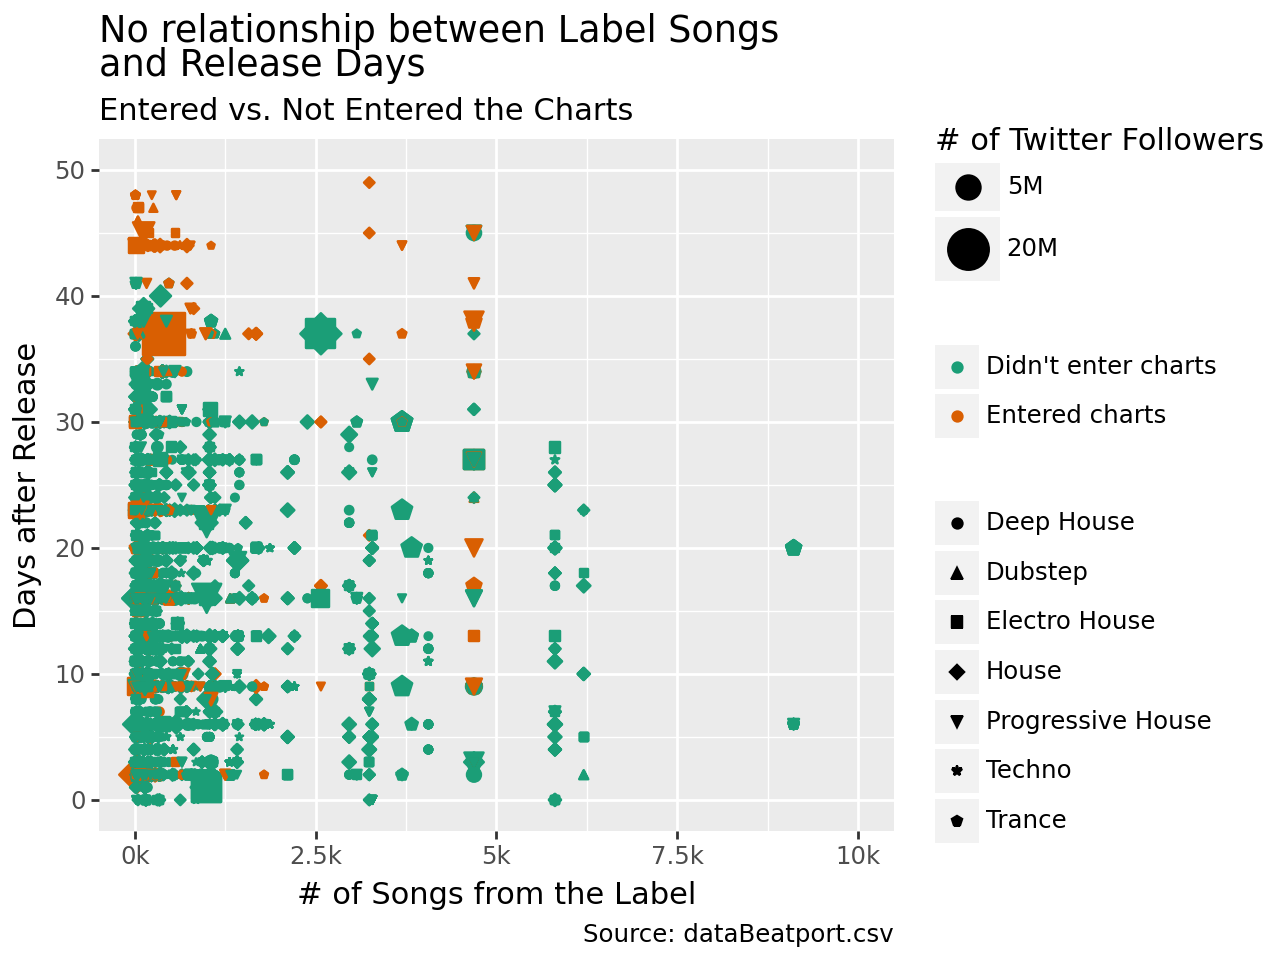

In [14]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50]) +
   scale_size_continuous(breaks = [5000000, 20000000],
                        labels = ["5M", "20M"],
                        range = [1,8]) +
   scale_color_brewer(labels = ["Didn't enter charts", "Entered charts"],
                       type = "qual", palette = "Dark2")
)

Let's say I want to switch the `enteredCharts` variable to size and `twitterFollowers` to color. I could use `scale_color_distiller()` instead since `twitterFollowers` is a continuous variable:

/opt/tljh/user/lib/python3.10/site-packages/plotnine/scales/scale_size.py:51: PlotnineWarning: Using size for a discrete variable is not advised.
/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


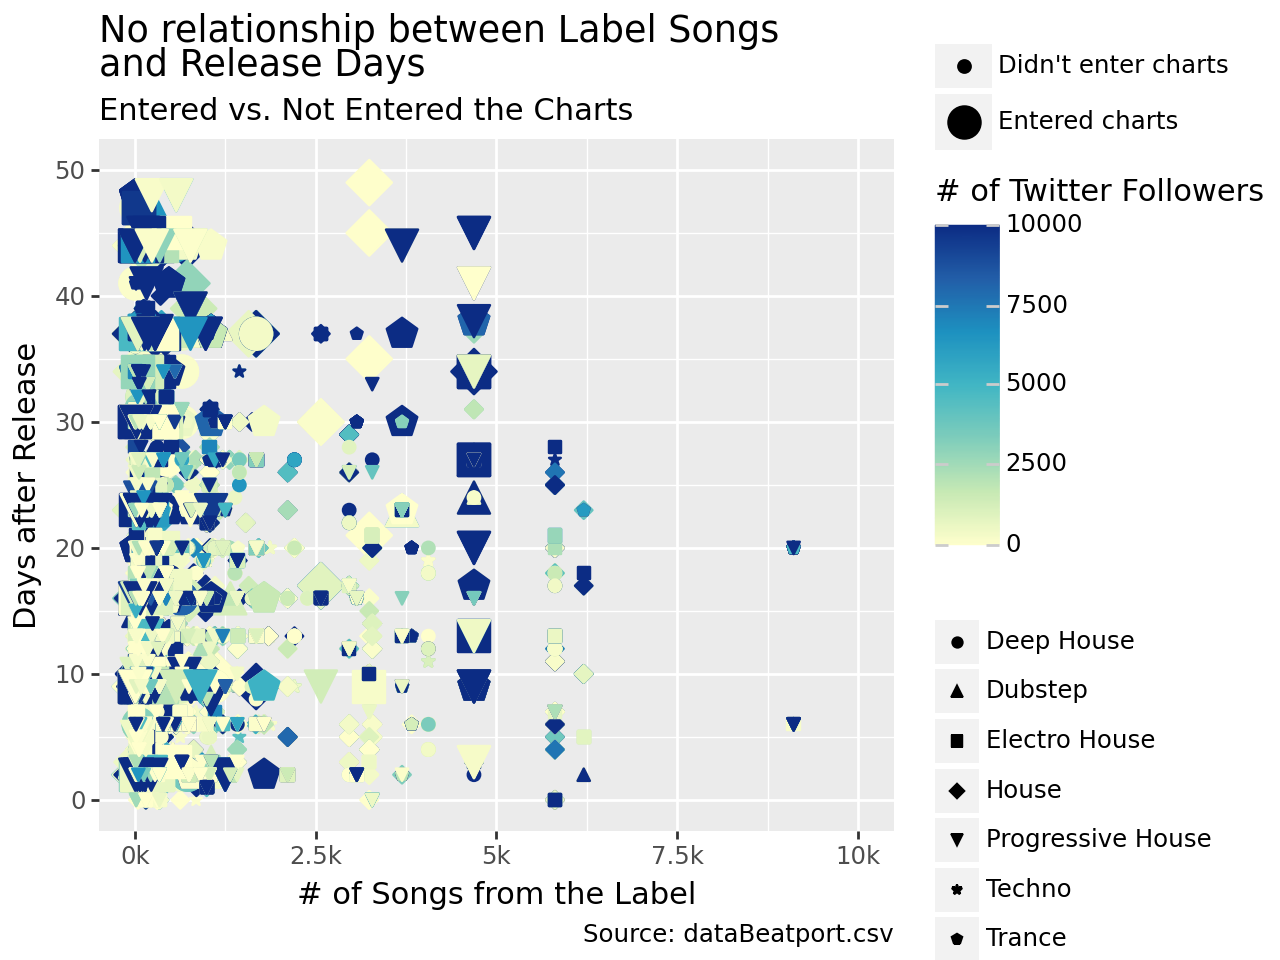

In [15]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", size = "factor(enteredCharts)",
               shape = "genre", color = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "# of Twitter Followers",
       shape = "",
       size = "") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50]) +
   scale_size_discrete(labels = ["Didn't enter charts", "Entered charts"]) +
   scale_color_distiller(limits = [0, 10000],
                         type = "seq", palette = "YlGnBu", direction = 1)
   # direction = 1 reverses the direction of the color scale
)

### Changing the Shapes

With the `shape` scale, you can specify specific shapes, again with the `values` setting. Let's say we wanted all genres with "House" in the name to be represented with circles ("o") and everything else with pluses ("+"):

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


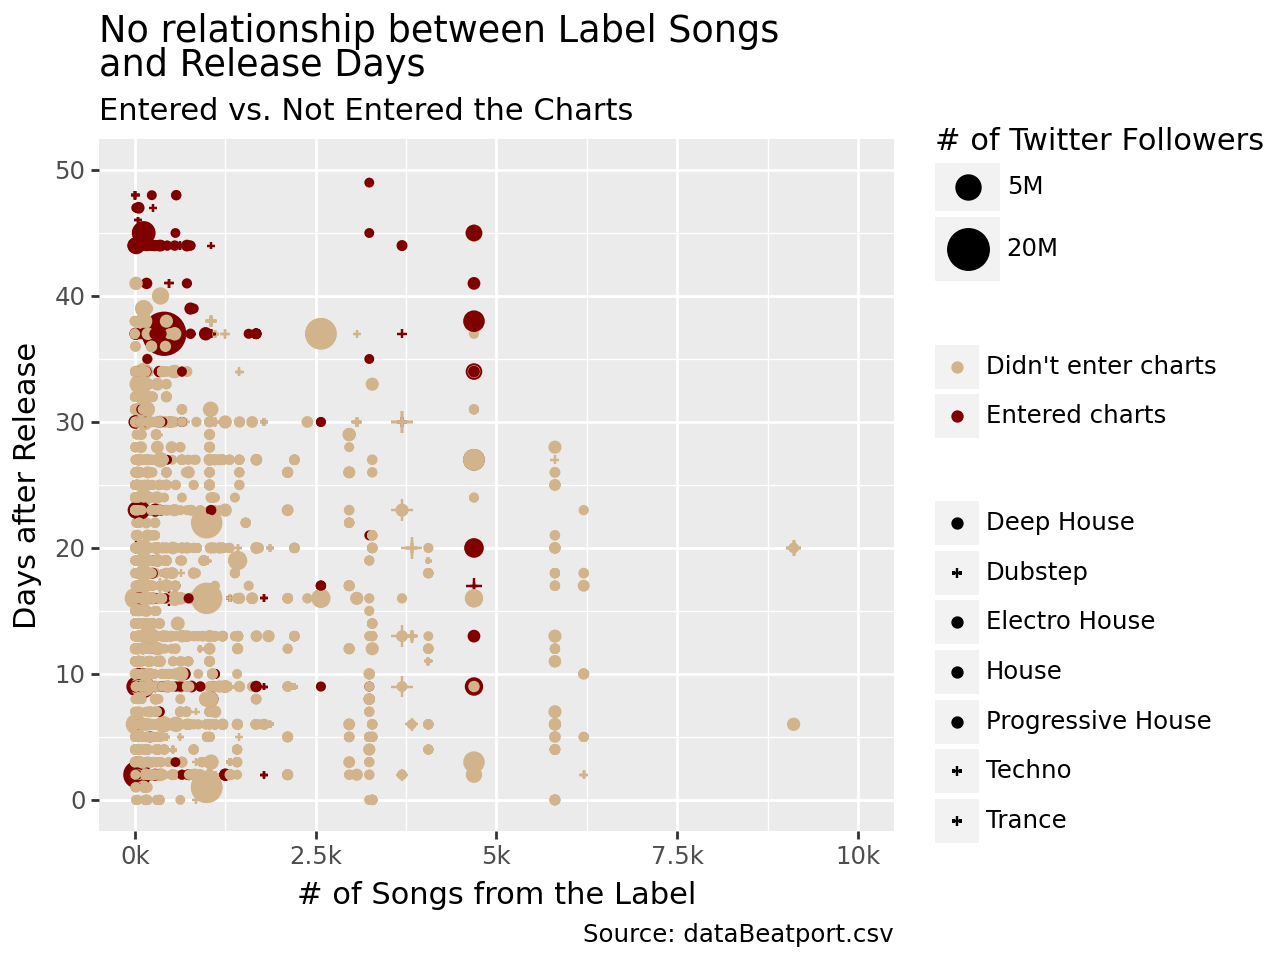

In [16]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50]) +
   scale_size_continuous(breaks = [5000000, 20000000],
                        labels = ["5M", "20M"],
                        range = [1,8]) +
   scale_color_manual(labels = ["Didn't enter charts", "Entered charts"],
                       values = ["tan", "maroon"]) +
   scale_shape_manual(values = {"Deep House": "o", "Dubstep": "+", "Electro House": "o",
                               "House": "o", "Progressive House": "o", "Techno": "+",
                               "Trance": "+"})
)

You can find a list of codes for shapes at this link: https://matplotlib.org/stable/api/markers_api.html.

If you'd like to change the order of the genre categories, you can use `limits` within the `scale_shape_discrete` layer...let's say I want all the genres with dots first and then the genres with pluses:

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


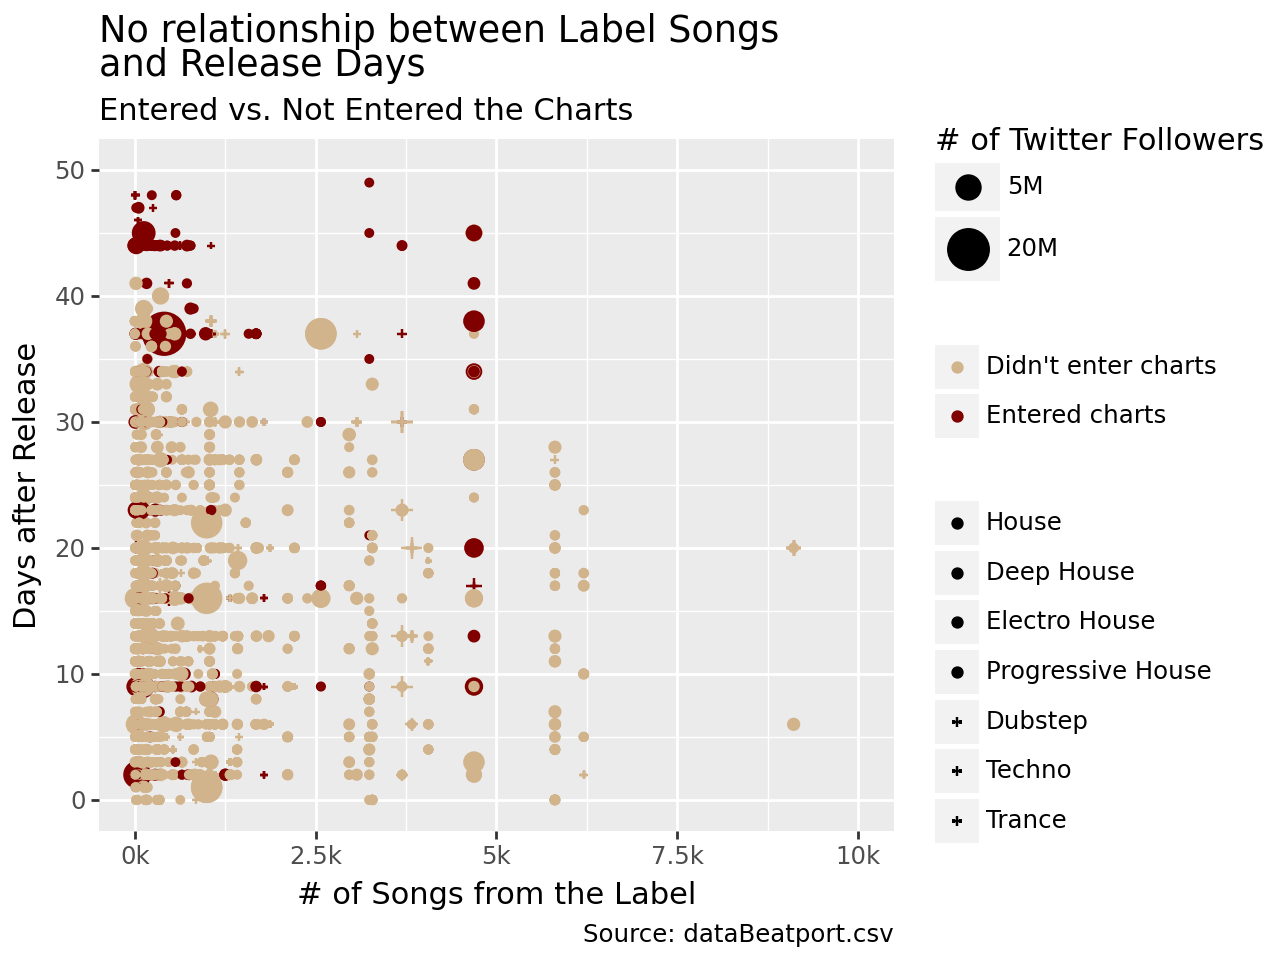

In [17]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50]) +
   scale_size_continuous(breaks = [5000000, 20000000],
                        labels = ["5M", "20M"],
                        range = [1,8]) +
   scale_color_manual(labels = ["Didn't enter charts", "Entered charts"],
                       values = ["tan", "maroon"]) +
   scale_shape_manual(values = {"Deep House": "o", "Dubstep": "+", "Electro House": "o",
                               "House": "o", "Progressive House": "o", "Techno": "+",
                               "Trance": "+"},
                     limits = ["House", "Deep House", "Electro House", "Progressive House",
                              "Dubstep", "Techno", "Trance"])
)

If you want to remove one of the genres, you would just drop it from the `limits` argument.

## Annotations

Using `scale` layers allow you to customize the appearance of any graphical elements that are mapped to a variable. What if you want to add an element that is not tied to a variable? You can do this with annotations.

The structure of the `annotate` layer is as follows:

```
  + annotate("annotationObject", x = x_coordinate, y = y_coordinate)
```

...where the x- and y-coordinates are where you want to center your annotation. You can also add on other settings like `color` and `size`.

The three annotation objects we'll cover are "text", "point", and "segment".

### Annotate: Text

You can use `"text"` to annotate text onto your graph. Let's label the point in the lower right corner of the graph as an outlier:

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


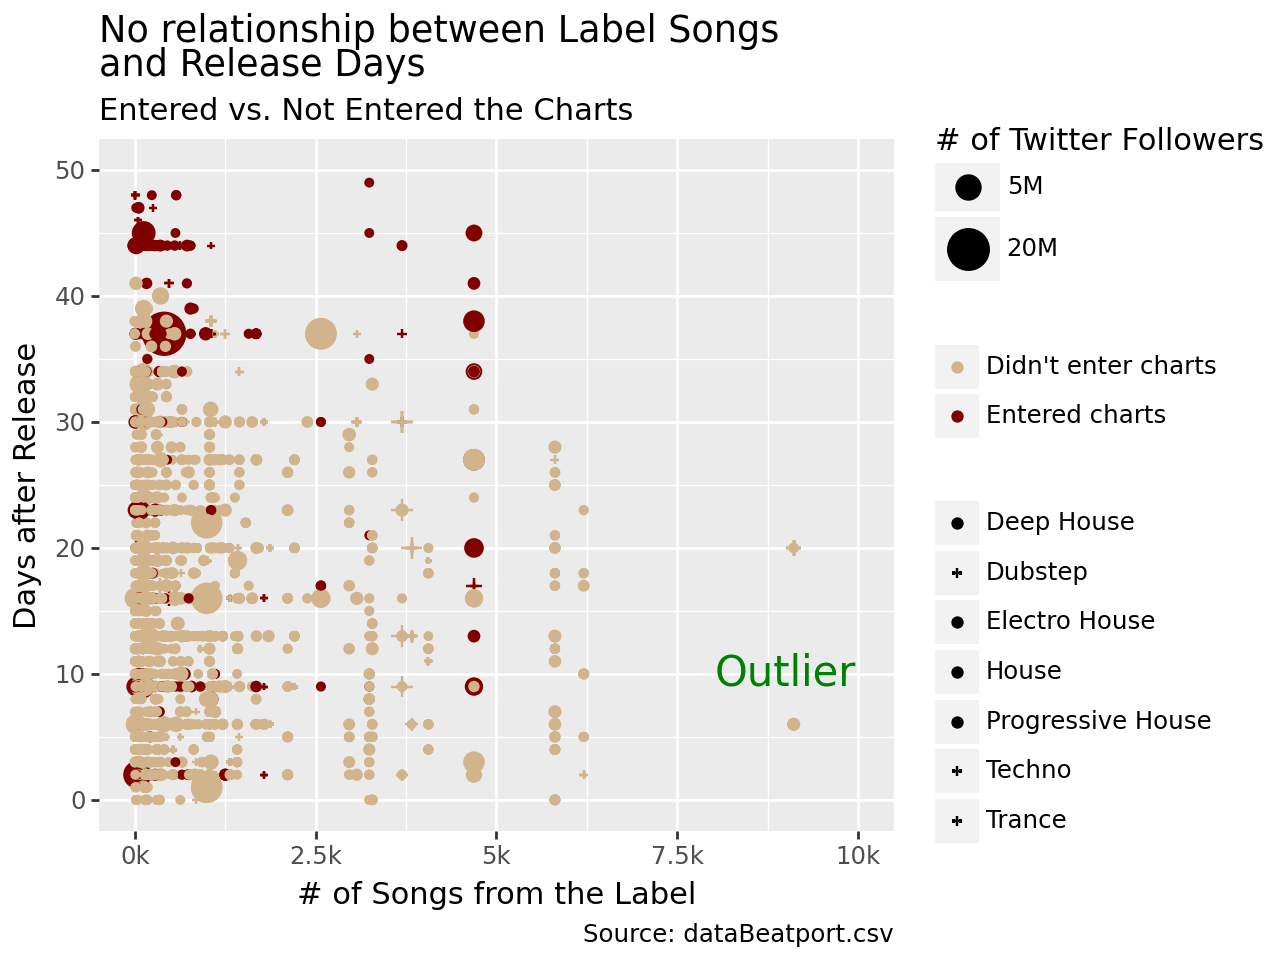

In [18]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50]) +
   scale_size_continuous(breaks = [5000000, 20000000],
                        labels = ["5M", "20M"],
                        range = [1,8]) +
   scale_color_manual(labels = ["Didn't enter charts", "Entered charts"],
                       values = ["tan", "maroon"]) +
   scale_shape_manual(values = {"Deep House": "o", "Dubstep": "+", "Electro House": "o",
                               "House": "o", "Progressive House": "o", "Techno": "+",
                               "Trance": "+"}) +
   annotate("text", label = "Outlier", x = 9000, y = 10, color = "green", size = 15)
)

The default is for annotated text to be centered at your `x` and `y` coordinates. However, you can use `ha` (horizontal alignment) to align `"left"` or `"right"` and you can use `va` (vertical alignment) to align `"top"` and `"bottom"`. Here's an example:

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


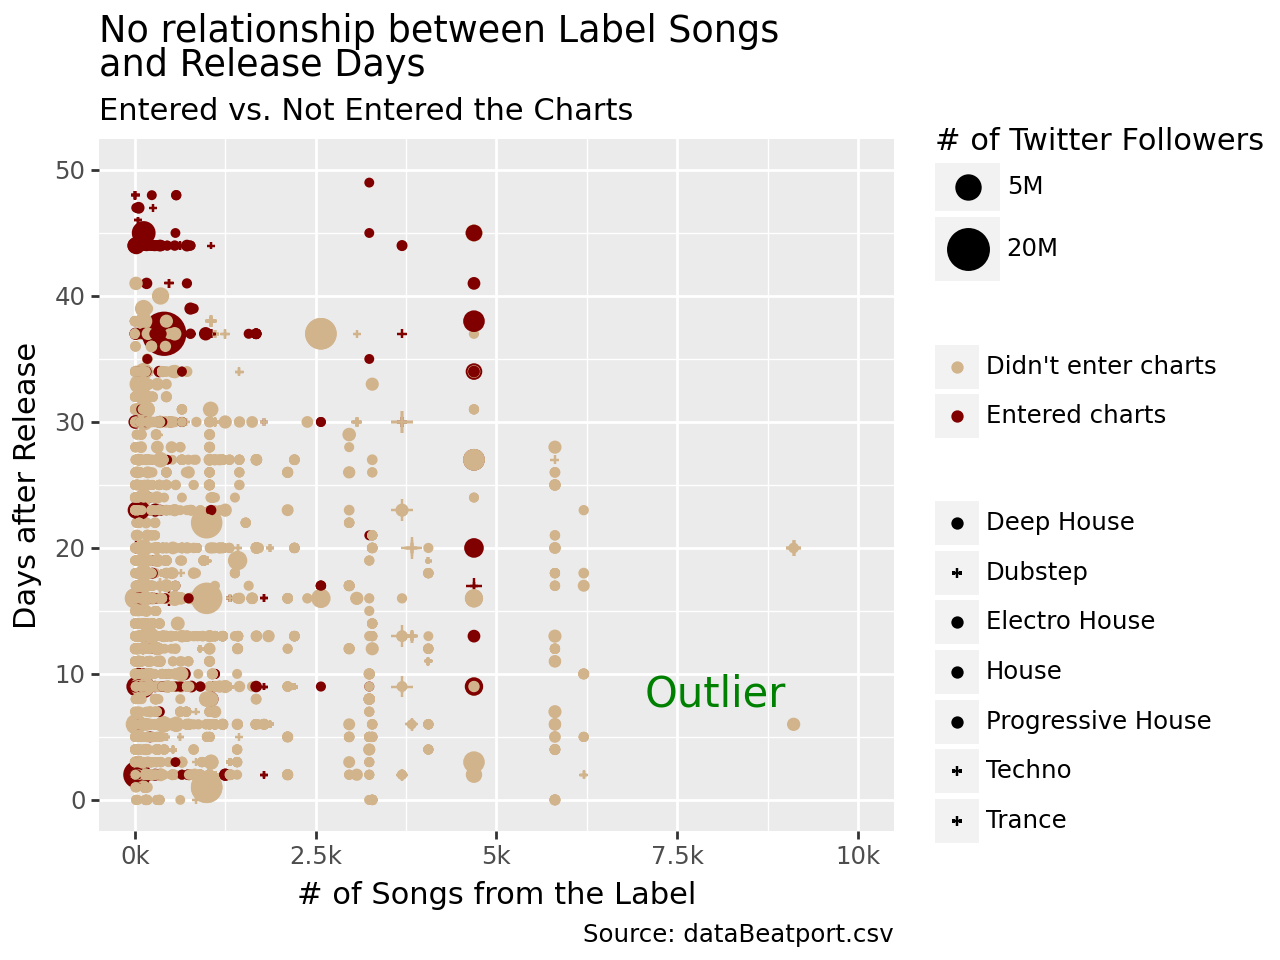

In [19]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50]) +
   scale_size_continuous(breaks = [5000000, 20000000],
                        labels = ["5M", "20M"],
                        range = [1,8]) +
   scale_color_manual(labels = ["Didn't enter charts", "Entered charts"],
                       values = ["tan", "maroon"]) +
   scale_shape_manual(values = {"Deep House": "o", "Dubstep": "+", "Electro House": "o",
                               "House": "o", "Progressive House": "o", "Techno": "+",
                               "Trance": "+"}) +
   annotate("text", label = "Outlier", x = 9000, y = 10, color = "green", size = 15,
           ha = "right", va = "top")
)

### Annotate: Point

We can annotate a `"point"` onto the graph, once again setting the coordinates for where it should be drawn. Let's label that outlier point with a large green dot:

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


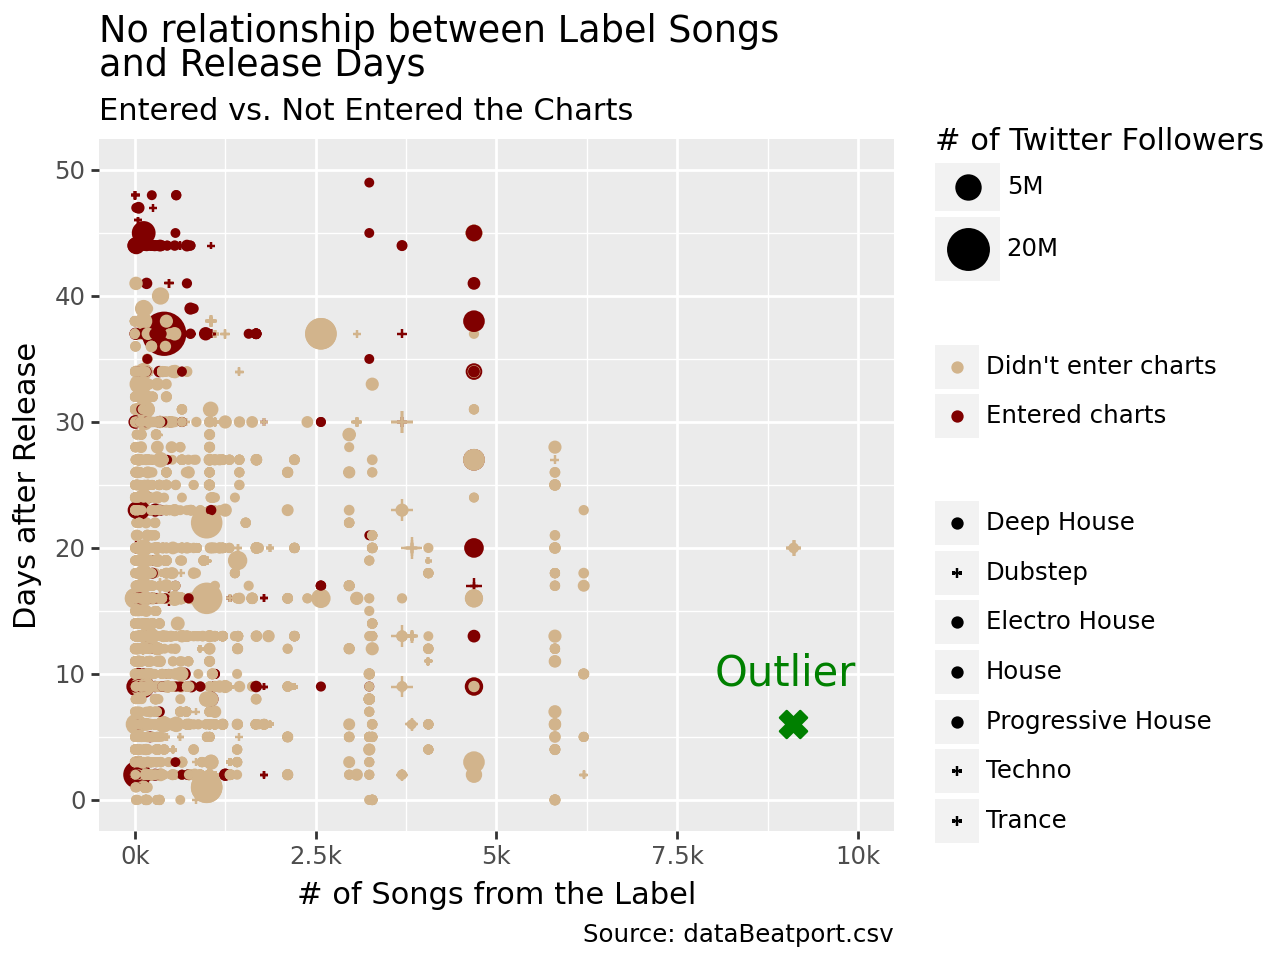

In [20]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50]) +
   scale_size_continuous(breaks = [5000000, 20000000],
                        labels = ["5M", "20M"],
                        range = [1,8]) +
   scale_color_manual(labels = ["Didn't enter charts", "Entered charts"],
                       values = ["tan", "maroon"]) +
   scale_shape_manual(values = {"Deep House": "o", "Dubstep": "+", "Electro House": "o",
                               "House": "o", "Progressive House": "o", "Techno": "+",
                               "Trance": "+"}) +
   annotate("text", label = "Outlier", x = 9000, y = 10, color = "green", size = 15) +
   annotate("point", x = 9100, y = 6, color = "green", size = 5, shape = "X")
)

### Annotate: Segment

To draw a line, you can annotate a `"segment"`. Because there's a starting and ending point for both the x- and y-coordinates, you need to specify each. Let's draw a dashed horizontal line for the mean value of "daysAfterRelease" (which is 15.4):

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


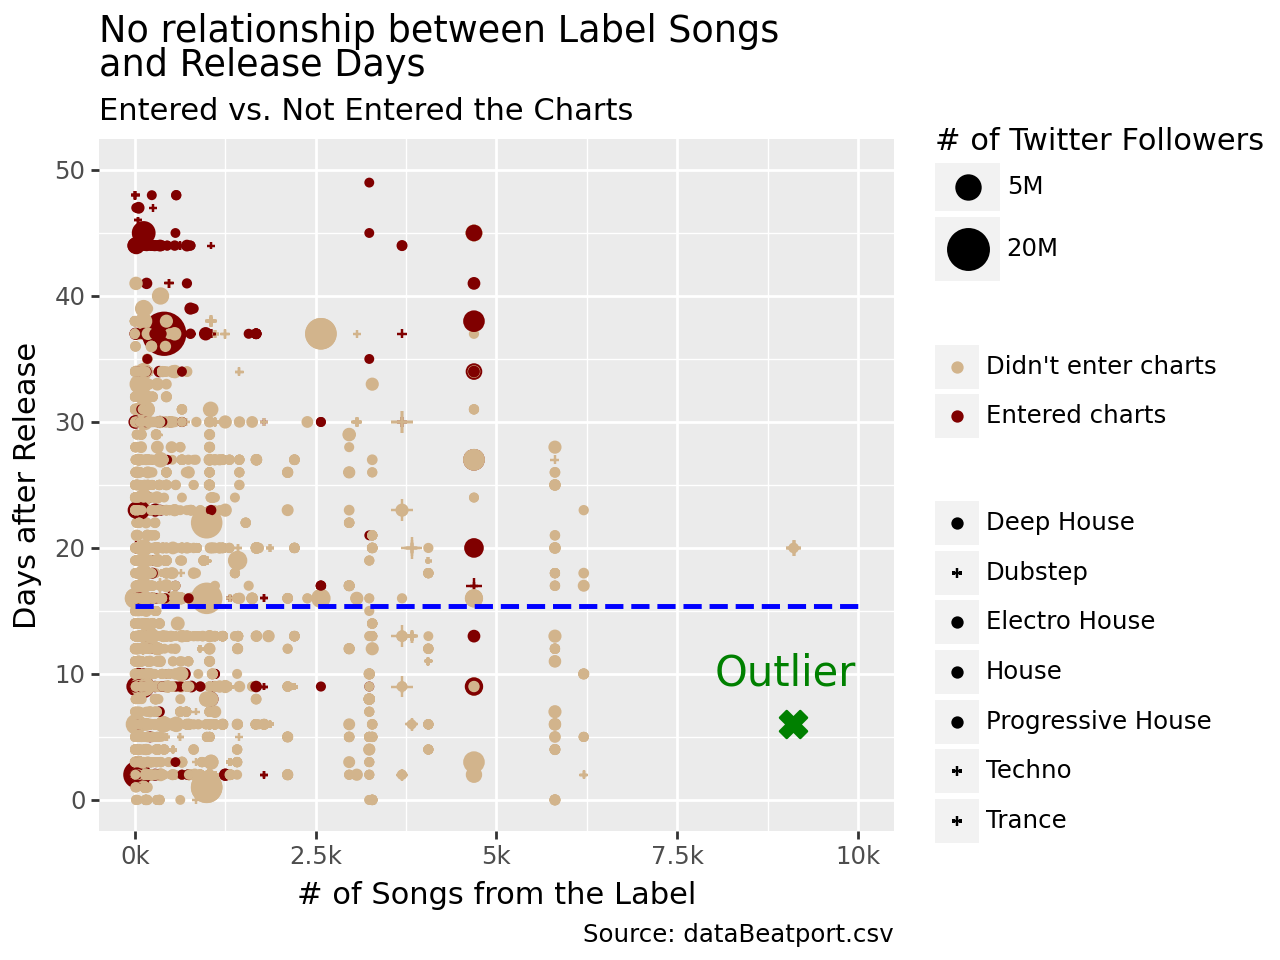

In [21]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50]) +
   scale_size_continuous(breaks = [5000000, 20000000],
                        labels = ["5M", "20M"],
                        range = [1,8]) +
   scale_color_manual(labels = ["Didn't enter charts", "Entered charts"],
                       values = ["tan", "maroon"]) +
   scale_shape_manual(values = {"Deep House": "o", "Dubstep": "+", "Electro House": "o",
                               "House": "o", "Progressive House": "o", "Techno": "+",
                               "Trance": "+"}) +
   annotate("text", label = "Outlier", x = 9000, y = 10, color = "green", size = 15) +
   annotate("point", x = 9100, y = 6, color = "green", size = 5, shape = "X") +
   annotate("segment", x = 0, xend = 10000, y = 15.4, yend = 15.4, linetype = "dashed", 
           color = "blue", size = 1)
)

We probably should label the line. Annotate text onto the graph (above the blue line) to indicate "Average Days" and use blue font color:

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


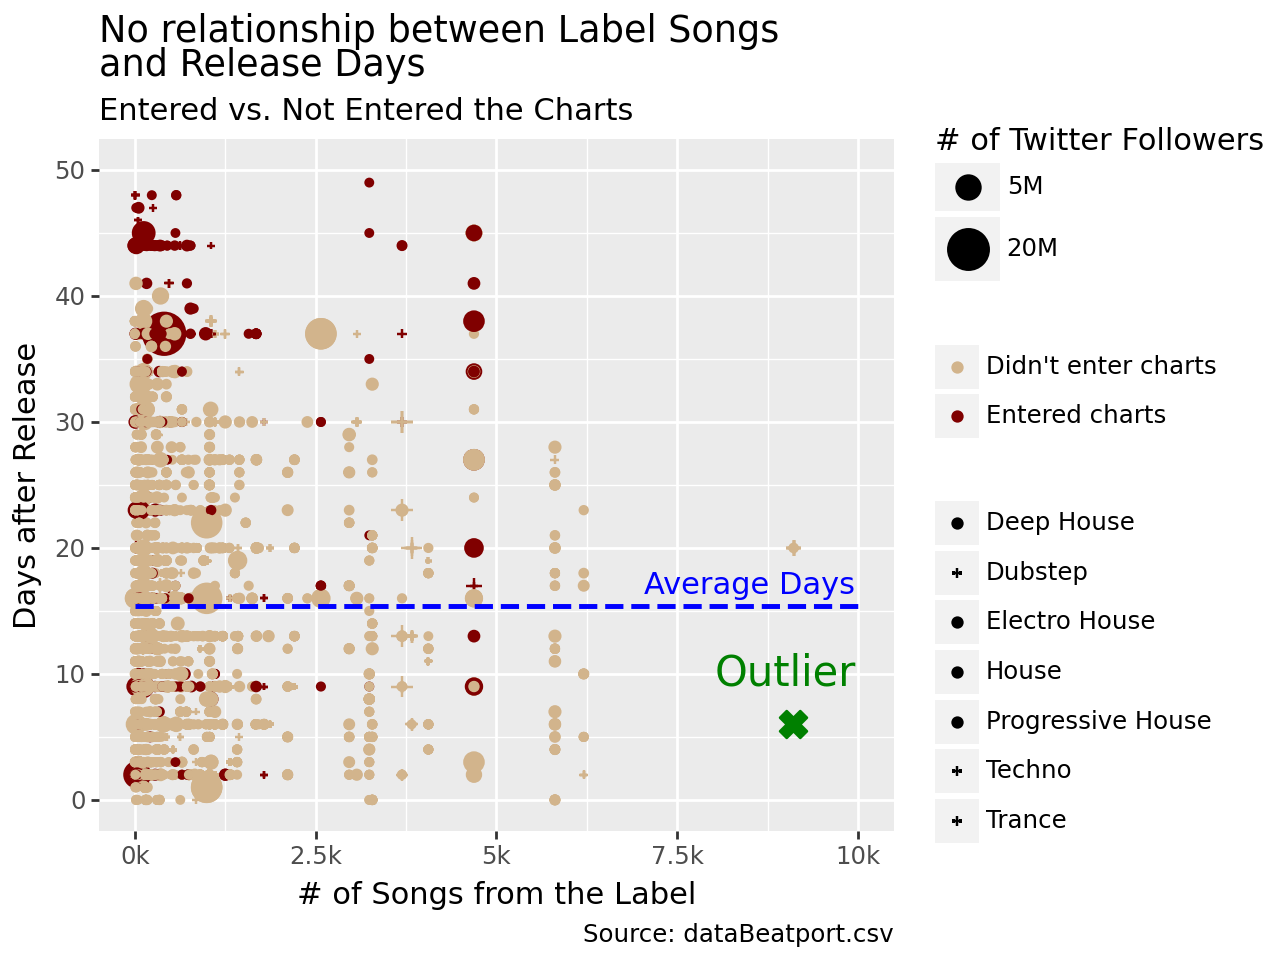

In [22]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50]) +
   scale_size_continuous(breaks = [5000000, 20000000],
                        labels = ["5M", "20M"],
                        range = [1,8]) +
   scale_color_manual(labels = ["Didn't enter charts", "Entered charts"],
                       values = ["tan", "maroon"]) +
   scale_shape_manual(values = {"Deep House": "o", "Dubstep": "+", "Electro House": "o",
                               "House": "o", "Progressive House": "o", "Techno": "+",
                               "Trance": "+"}) +
   annotate("text", label = "Outlier", x = 9000, y = 10, color = "green", size = 15) +
   annotate("point", x = 9100, y = 6, color = "green", size = 5, shape = "X") +
   annotate("segment", x = 0, xend = 10000, y = 15.4, yend = 15.4, linetype = "dashed", 
           color = "blue", size = 1) +
   annotate("text", label = "Average Days", x = 8500, y = 17, color = "blue")
)

## Practice

Re-create the following bar chart:

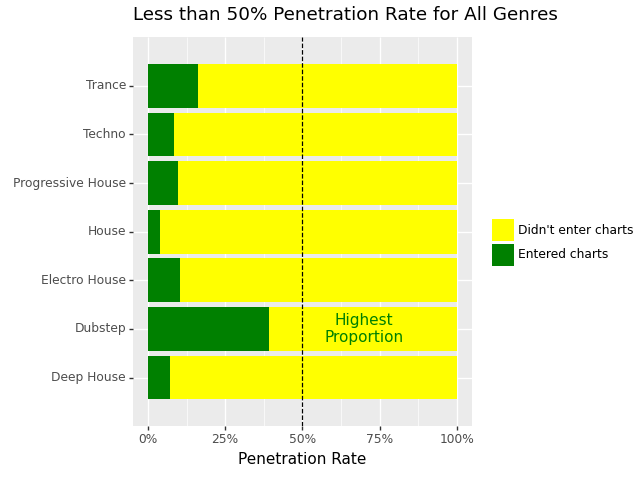

The following are hints that might help you:

* The variables I used are "genre" and "enteredCharts"
* Remember to use `factor()` to convert "enteredCharts" to categorical
* Similar to `scale_color_manual()`, there's also a `scale_fill_manual()` and the colors I used are "yellow" and "green"
* For the dashed line, x = 0 and xend = 8

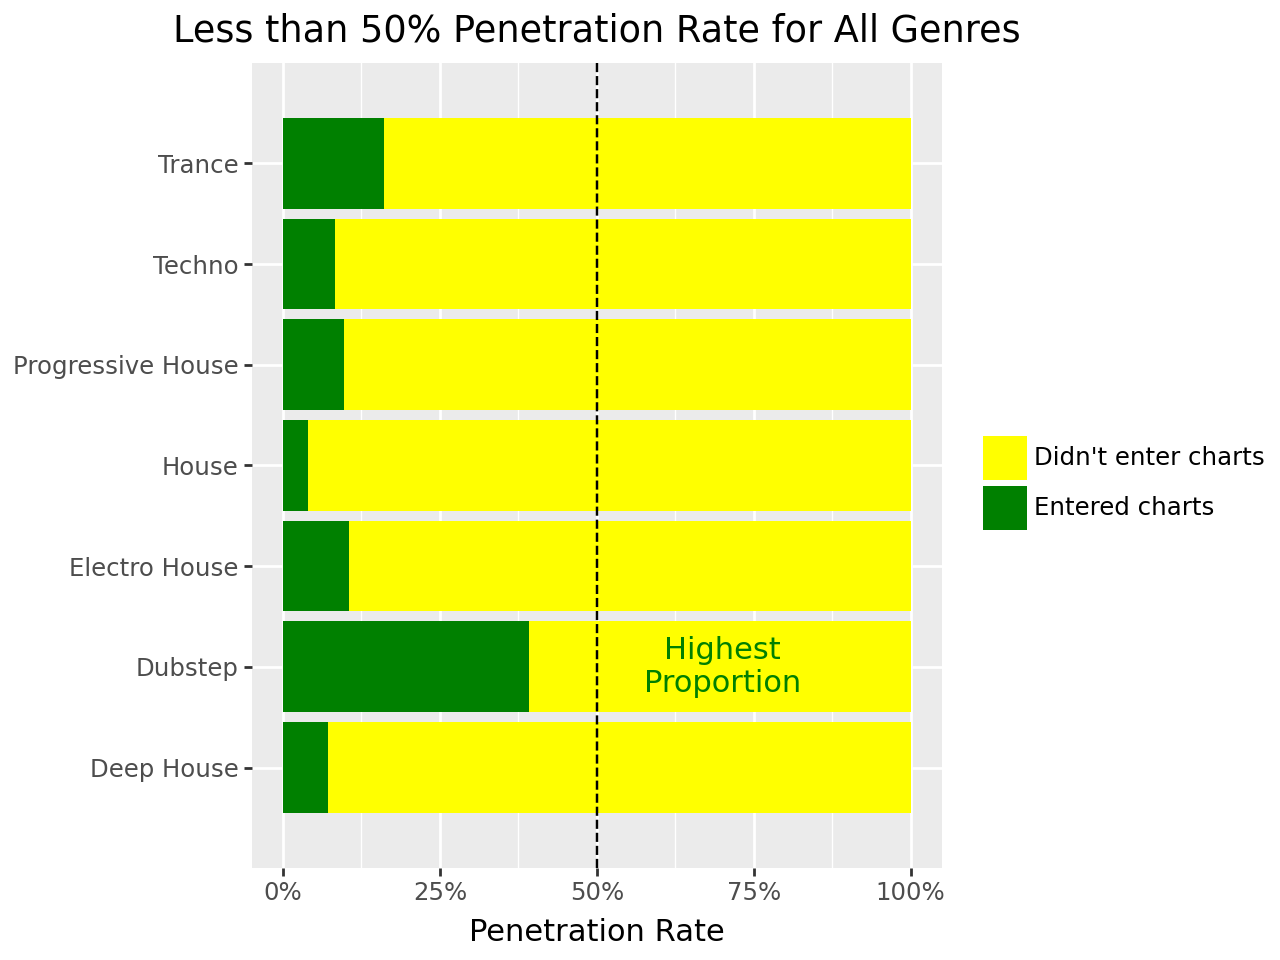

In [23]:
(ggplot(df, aes("genre", fill = "factor(enteredCharts)")) +
   geom_bar(position = "fill") +
   coord_flip() +
   labs(title = "Less than 50% Penetration Rate for All Genres",
       x = "", 
       fill = "",
       y = "Penetration Rate") +
   scale_y_continuous(labels = ["0%", "25%", "50%", "75%", "100%"]) +
   scale_fill_manual(labels = ["Didn't enter charts", "Entered charts"],
                     values = ["yellow", "green"]) +
   annotate("text", label = "Highest\nProportion", y = 0.7, x = "Dubstep", color = "green") +
   annotate("segment", x = 0, xend = 8, y = 0.5, yend = 0.5, linetype = "dashed"))

## Going Further...Themes

There's even more that you can do to customize the appearance of your graph. Adding `theme` layers allows you to adjust the overall appearance. For example, here's a revised version of the graph we've been working with:

/opt/tljh/user/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 482 rows containing missing values.


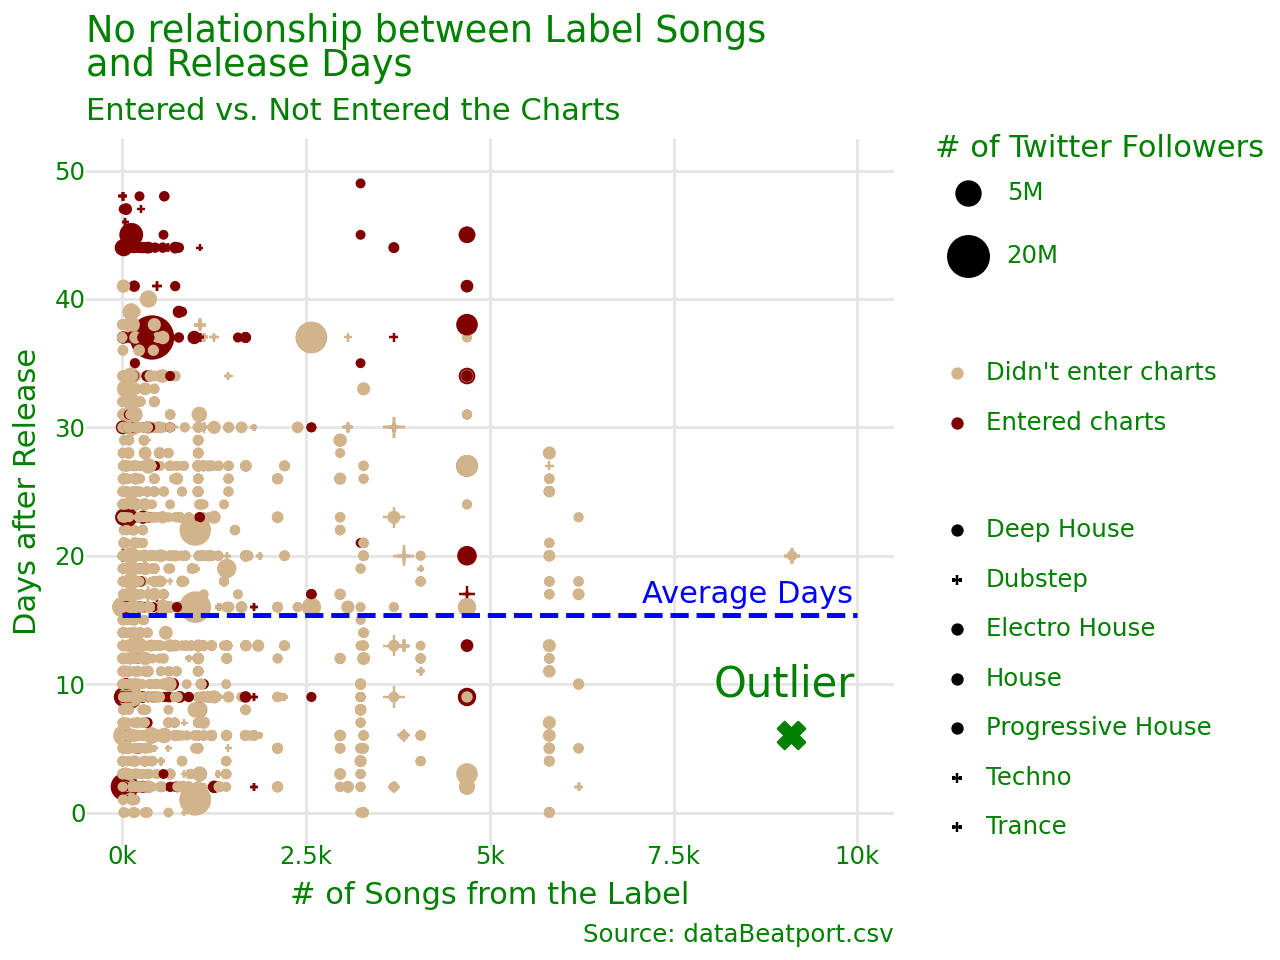

In [24]:
(ggplot(df, aes(x = "labelSongs", y = "daysAfterRelease", color = "factor(enteredCharts)",
               shape = "genre", size = "twitterFollowers")) +
   geom_point()   +
   labs(title = "No relationship between Label Songs \nand Release Days",
       subtitle = "Entered vs. Not Entered the Charts",
       caption = "Source: dataBeatport.csv",
       x = "# of Songs from the Label",
       y = "Days after Release",
       color = "",
       shape = "",
       size = "# of Twitter Followers") +
   scale_x_continuous(breaks = [0, 2500, 5000, 7500, 10000, 12500, 15000],
                     labels = ["0k", "2.5k", "5k", "7.5k", "10k", "12.5k", "15k"],
                     limits = [0,10000]) +
   scale_y_continuous(breaks = [0, 10, 20, 30, 40, 50],
                     limits = [0,50]) +
   scale_size_continuous(breaks = [5000000, 20000000],
                        labels = ["5M", "20M"],
                        range = [1,8]) +
   scale_color_manual(labels = ["Didn't enter charts", "Entered charts"],
                       values = ["tan", "maroon"]) +
   scale_shape_manual(values = {"Deep House": "o", "Dubstep": "+", "Electro House": "o",
                               "House": "o", "Progressive House": "o", "Techno": "+",
                               "Trance": "+"}) +
   annotate("text", label = "Outlier", x = 9000, y = 10, color = "green", size = 15) +
   annotate("point", x = 9100, y = 6, color = "green", size = 5, shape = "X") +
   annotate("segment", x = 0, xend = 10000, y = 15.4, yend = 15.4, linetype = "dashed", 
           color = "blue", size = 1) +
   annotate("text", label = "Average Days", x = 8500, y = 17, color = "blue") +
   theme_minimal() +
   theme(text = element_text(color = "green"),
        panel_grid_minor = element_blank())
)

The syntax of `theme` layers are a bit more complicated. However, if you're interested in going further, here's a link to the plotnine documentation: https://plotnine.org/reference/#themes